# POST SSE 이벤트 설계

**이 노트북에서 할 일**

1. 실습 앱의 처리 함수 `chat_stream`이 진행 값을 SSE 사건으로 내놓는 줄을 읽습니다.
2. 시험용 클라이언트로 받은 응답 글을 SSE 사건으로 나누고, 칸마다 읽습니다.
3. 인자 `response_class` 하나만 빼면 같은 처리 함수의 응답이 어떻게 바뀌는지 실험합니다.

**준비물** — 이 노트북은 모델을 부르지 않습니다.
모델 요청은 0번이고, API 키 없이 실행합니다.
예상 비용도 0달러입니다.
실습 앱의 에이전트 그래프는 모델을 쓰지 않고, 정해 둔 말로 답합니다.
그래서 다시 실행해도 같은 값이 나와야 합니다.

요청은 시험용 클라이언트로 같은 노트북 안에서 보냅니다.
서버 프로그램을 띄우지 않고, 네트워크와 포트를 쓰지 않습니다.
실습 폴더의 파일을 가져오고 읽기만 하며, 쓰는 파일은 없습니다.

걸린 시간은 재지 않았습니다.
이 절은 응답 글에 적힌 사건의 차례와 칸만 봅니다.
앞 챕터에서 배운 함수는 이 절에서 쓰지 않아, 도구 파일도 가져오지 않습니다.

**기준 버전** — 첫 셀에서 패키지 여섯을 설치합니다.
판은 fastapi 0.135.0, httpx 0.28.1, pydantic 2.12.5, starlette 1.6.0입니다.
패키지 langgraph 1.2.11과 langchain 1.4.0은 실습 앱 파일이 가져오는 패키지입니다.
여섯 모두 실습 폴더 잠금과 같은 판입니다.

교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~3절을 읽고, 4절 실험의 가설을 함께 세웁니다.
4절의 두 실행은 실습 시간에 실행합니다.

실습 폴더 `labs/part7/ch30-fastapi-serving`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![위에서 아래로 읽는 흐름도입니다. 초록 상자 요청 본문 질문 반납 기한을 알려 주세요와 thread_id sse-1에서 초록 상자 처리 함수 chat_stream이 astream 모드 custom을 부름으로 이어집니다. 노란 상자 진행 값 여섯 칸 token 하나씩을 지나, 초록 상자 진행 값마다 yield로 사건 이름 token과 사건 번호 sse-1:0에서 sse-1:5, 초록 상자 끝에 yield로 사건 이름 done 하나 사건 번호 없음으로 갑니다. 이어서 회색 상자 라이브러리가 사건마다 줄 event data id로 적음을 지나 노란 상자 응답 본문 SSE 사건 일곱 text/event-stream에 닿는 그림](attachment:05-1-진행-값에서-SSE-사건까지.png)

위에서 아래로 읽습니다.
초록 상자는 우리가 보낸 요청 본문과 실습 앱 파일의 줄이고, 회색 상자는 라이브러리가 하는 일입니다.
노란 상자 둘은 노트북 2절과 3절의 출력입니다.
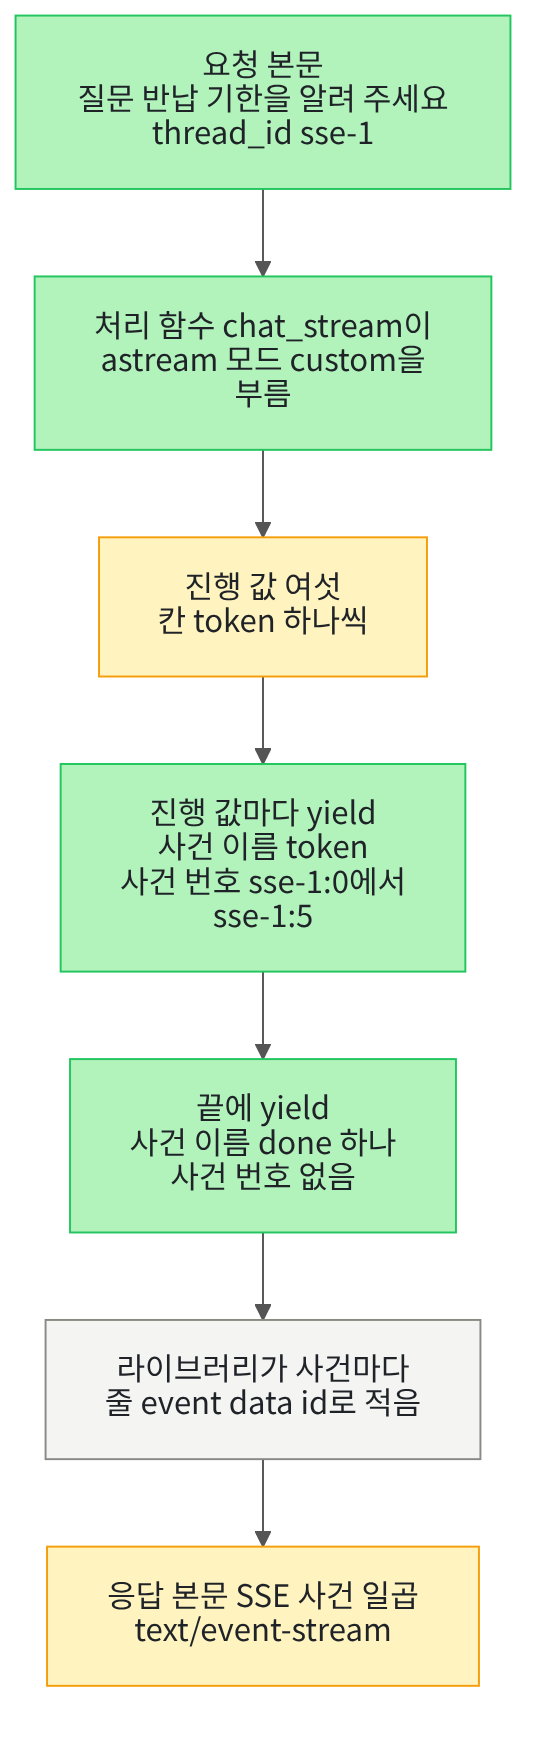

## 1. 준비

04절에서는 비동기 메서드 `astream`으로 노드의 진행 값을 같은 프로그램 안에서 받았습니다.
이 절은 그 진행 값을 웹 응답에 실어 보내는 처리 함수를 봅니다.
제목의 SSE는 Server-Sent Events의 줄임말입니다.
서버가 한 응답 안에서 사건을 차례로 글로 적어 보내는 형식입니다.
제목의 POST는 01절에서 본 요청 방식이고, 제목의 이벤트는 이 절에서 SSE 사건이라고 부릅니다.

첫 셀은 패키지 여섯을 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "fastapi==0.135.0" "httpx==0.28.1" "pydantic==2.12.5" "starlette==1.6.0" "langgraph==1.2.11" "langchain==1.4.0"
from importlib.metadata import version

print("fastapi:", version("fastapi"))
print("httpx:", version("httpx"))
print("pydantic:", version("pydantic"))
print("starlette:", version("starlette"))
print("langgraph:", version("langgraph"))
print("langchain:", version("langchain"))

Note: you may need to restart the kernel to use updated packages.


fastapi: 0.135.0
httpx: 0.28.1
pydantic: 2.12.5
starlette: 1.6.0
langgraph: 1.2.11
langchain: 1.4.0


**결과 읽기** — 출력 줄 `fastapi: 0.135.0`과 `langgraph: 1.2.11`이 보입니다.
여섯 모두 실습 폴더 잠금과 같은 판이고, 04절과 같은 목록입니다.
FastAPI 문서는 이 절에서 쓰는 SSE 기능이 0.135.0에서 들어왔다고 적습니다.
이 절은 모델 객체를 만들지 않아, API 키를 확인하는 셀도 없습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
모듈 `json`은 JSON 글을 파이썬 값으로 읽을 때 씁니다.
모듈 `fastapi.sse`에서는 SSE 응답에 쓰는 이름 둘을 가져옵니다.

In [2]:
# 이 절에서 쓸 이름을 가져옵니다(os·json은 Python에 들어 있는 모듈입니다)
import os
import json
from fastapi import FastAPI
from fastapi.sse import EventSourceResponse, ServerSentEvent
from fastapi.testclient import TestClient

print("가져온 이름:", "json, FastAPI, TestClient")
print("fastapi.sse에서 가져온 이름:", "EventSourceResponse, ServerSentEvent")

가져온 이름: json, FastAPI, TestClient
fastapi.sse에서 가져온 이름: EventSourceResponse, ServerSentEvent


**결과 읽기** — 출력 줄 `fastapi.sse에서 가져온 이름: EventSourceResponse, ServerSentEvent`가 보입니다.
클래스 `EventSourceResponse`는 SSE로 보내는 응답의 종류를 가리킵니다.
클래스 `ServerSentEvent`는 SSE 사건 하나의 칸을 담는 양식 클래스입니다.
두 이름은 2절에서 앱 파일의 줄로 먼저 보고, 4절에서 우리가 직접 씁니다.

다음 셀은 01절 2절과 같은 파일 위치 셀로, 후보 셋 가운데 실습 폴더를 고릅니다.

In [3]:
# 노트북을 연 자리에서 본 실습 폴더의 위치를 후보 셋 가운데에서 고릅니다
candidates = ["..", ".", "labs/part7/ch30-fastapi-serving"]
lab_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/agent_service/schemas.py"):
        lab_path = candidate
        break
print("실습 폴더를 찾았는가:", lab_path is not None)
assert lab_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."

실습 폴더를 찾았는가: True


**결과 읽기** — 출력 줄 `실습 폴더를 찾았는가: True`가 보입니다.
고른 후보는 연 자리마다 달라서 출력하지 않습니다.

다음 셀은 04절처럼 작업 폴더를 실습 폴더로 옮긴 뒤 이름을 가져옵니다.
그래프 파일에서 에이전트 그래프 `agent`를, 앱 파일에서 앱 객체 `app`과 처리 함수 `chat_stream`을 가져옵니다.
입력 형식 파일에서는 요청 본문의 양식 클래스 `ChatRequest`를 가져옵니다.

In [4]:
# 작업 폴더를 실습 폴더로 옮기고, 그래프·앱 객체·처리 함수·양식 클래스를 가져옵니다
os.chdir(lab_path)
from agent_service.agent import agent
from agent_service.app import app, chat_stream
from agent_service.schemas import ChatRequest
print("가져온 앱 객체의 종류:", type(app).__name__)
print("가져온 처리 함수의 이름:", chat_stream.__name__)

가져온 앱 객체의 종류: FastAPI
가져온 처리 함수의 이름: chat_stream


**결과 읽기** — 출력 줄 `가져온 앱 객체의 종류: FastAPI`와 `가져온 처리 함수의 이름: chat_stream`이 보입니다.
양식 클래스 `ChatRequest`는 01절에서 읽은 입력 형식으로, 칸 `question`과 `thread_id`를 받습니다.

## 2. 처리 함수 chat_stream과 yield

04절 6절에서는 앱 파일 110·111행이 모드 `custom`으로 `astream`을 부르는 것을 봤습니다.
그 두 줄은 처리 함수 `chat_stream` 안에 있습니다.
다음 셀은 앱 파일을 글로 읽어, 사건 번호를 만드는 함수와 `chat_stream`의 줄을 줄 번호와 함께 출력합니다.

In [5]:
# 앱 파일을 글로 읽어, 95~124행(함수 _event_id와 처리 함수 chat_stream)을 줄 번호와 함께 출력합니다
first_line = 95
last_line = 124
with open("agent_service/app.py", encoding="utf-8") as app_file:
    app_lines = app_file.read().splitlines()
print("줄 번호 | 줄")
for index in range(first_line - 1, last_line):
    print(index + 1, "|", app_lines[index])

줄 번호 | 줄
95 | def _event_id(thread_id: str, index: int) -> str:
96 |     return f"{thread_id}:{index}"
97 | 
98 | 
99 | @app.post("/v1/chat/stream", response_class=EventSourceResponse)
100 | async def chat_stream(
101 |     body: ChatRequest,
102 |     runtime: AgentDep,
103 |     _token: AuthDep,
104 |     timeout: TimeoutDep,
105 |     start: ResumeIndexDep,
106 | ) -> AsyncIterable[ServerSentEvent]:
107 |     index = 0
108 |     try:
109 |         async with asyncio.timeout(timeout):
110 |             async for chunk in runtime.astream(
111 |                 {"messages": [body.question]}, stream_mode="custom"
112 |             ):
113 |                 if index >= start:
114 |                     yield ServerSentEvent(
115 |                         data=chunk, event="token", id=_event_id(body.thread_id, index)
116 |                     )
117 |                 index += 1
118 |         yield ServerSentEvent(data={"thread_id": body.thread_id}, event="done")
119 |     except Exception:
1

**결과 읽기** — 라벨 줄 아래 99행은 `99 | @app.post("/v1/chat/stream", response_class=EventSourceResponse)`입니다.
데코레이터 줄의 인자 `response_class`가 이 처리 함수의 응답을 SSE로 보내게 합니다.
114~116행은 받은 진행 값마다 `ServerSentEvent`를 만들어 `yield`로 내놓습니다.
칸 `data`에 진행 값, 칸 `event`에 사건 이름 `token`, 칸 `id`에 사건 번호를 넣습니다.
118행은 반복이 끝난 뒤, 사건 이름이 `done`인 사건을 하나 더 내놓습니다.

사건 번호는 95~96행 함수 `_event_id`가 스레드 이름과 자리 번호를 `:`로 이어 만듭니다.
여기서 스레드는 칸 `thread_id`가 가리키는 대화 하나(Ch 23 01절)로, 01·03절에서 말한 실행 흐름의 스레드와 뜻이 다릅니다.
113행의 `start`는 이어 받을 자리이고, 117행은 자리 번호를 하나씩 키웁니다.
이어 받기와 119~124행의 오류 사건 `error`는 06절에서 봅니다.

109행 `async with asyncio.timeout(timeout):`은 들여 쓴 줄 전체에 시간 제한을 겁니다.
Python 문서는 정한 초를 넘기면 그 일을 취소하고, 오류 `TimeoutError`로 바꾼다고 적습니다.
02절에서 본 `asyncio.wait_for`와 같은 일을, 여러 줄을 감싸는 모양으로 합니다.
이 절에서는 시간 제한을 넘기는 장면을 실행하지 않았고, 06절에서 봅니다.

다음 셀은 처리 함수 `chat_stream`을 HTTP 없이 바로 불러, 받은 값의 종류를 봅니다.
02절에서 제공 함수를 직접 불렀듯, 의존성이 넘겨 줄 값을 우리가 인자로 적습니다.
시간 제한은 앱의 제공 함수 `get_timeout`이 내놓는 2.0초로, 이어 받을 자리는 처음인 0으로 둡니다.

In [6]:
# 처리 함수 chat_stream을 HTTP 없이 바로 불러, 받은 값의 종류를 봅니다
request_body = ChatRequest(question="반납 기한을 알려 주세요", thread_id="sse-1")
timeout_seconds = 2.0
# 의존성이 넘겨 줄 값(그래프·접근 토큰·시간 제한 초·이어 받을 자리)을 인자로 직접 적습니다
direct_stream = chat_stream(
    body=request_body, runtime=agent, _token="local-demo-token",
    timeout=timeout_seconds, start=0,
)
print("부르기만 해서 받은 값의 종류:", type(direct_stream).__name__)

부르기만 해서 받은 값의 종류: async_generator


**결과 읽기** — 출력 줄 `부르기만 해서 받은 값의 종류: async_generator`가 보입니다.
04절에서 `astream`을 부르기만 했을 때와 같은 종류입니다.
이 줄에서는 몸통이 아직 실행되지 않았고, 그래프도 부르지 않았습니다.

정의 줄이 `async def`이고 몸통에 `yield`가 있는 함수를 비동기 제너레이터 함수라고 합니다.
부르면 몸통을 바로 실행하지 않고, 04절에서 본 비동기 제너레이터를 내놓습니다.
값을 하나 꺼낼 때마다 몸통이 다음 `yield` 줄까지 실행되어, 그 줄의 값을 내놓고 멈춥니다.
빵을 한 판 구울 때마다 진열대에 내놓고, 다음 판은 멈춘 자리에서 이어 굽는 일과 같습니다.
B 트랙에서 Ch 2 09절을 배웠다면, 그 절의 `yield`를 `async def` 안에 쓴 모양입니다.

다음 셀은 04절처럼 `async for`로 값을 꺼내, 종류와 칸 셋을 한 줄씩 출력합니다.

In [7]:
# async for로 처리 함수가 yield로 내놓은 값을 꺼내, 종류와 칸 셋을 한 줄씩 출력합니다
yielded_items = []
print("종류 | event | id | data")
async for item in direct_stream:
    print(type(item).__name__, "|", item.event, "|", item.id, "|", item.data)
    yielded_items.append(item)
print("내놓은 값 수:", len(yielded_items))

종류 | event | id | data
ServerSentEvent | token | sse-1:0 | {'token': '질문을 '}
ServerSentEvent | token | sse-1:1 | {'token': '확인했습니다: '}
ServerSentEvent | token | sse-1:2 | {'token': '반납 '}
ServerSentEvent | token | sse-1:3 | {'token': '기한을 '}
ServerSentEvent | token | sse-1:4 | {'token': '알려 '}
ServerSentEvent | token | sse-1:5 | {'token': '주세요 '}
ServerSentEvent | done | None | {'thread_id': 'sse-1'}
내놓은 값 수: 7


**결과 읽기** — 라벨 줄 아래 첫 줄은 `ServerSentEvent | token | sse-1:0 | {'token': '질문을 '}`입니다.
여섯째 줄까지 사건 이름은 `token`이고, 사건 번호가 `sse-1:0`부터 `sse-1:5`까지 하나씩 커집니다.
마지막 줄은 `ServerSentEvent | done | None | {'thread_id': 'sse-1'}`로, 사건 번호가 없습니다.
출력 줄 `내놓은 값 수: 7`도 보입니다.

칸 `data`의 여섯 값은 04절에서 받은 진행 값과 같은 모양입니다.
115행 `data=chunk`가 받은 진행 값을 그대로 넣기 때문입니다.
여기까지는 파이썬 객체이고, 아직 웹 응답의 글이 아닙니다.

## 3. 응답 글을 SSE 사건으로 나누기

이제 같은 질문을 HTTP 요청으로 보냅니다.
01절의 시험용 클라이언트로 요청 방식 POST를 보내고, 요청 머리에는 02절의 교재용 접근 토큰을 담습니다.
다음 셀은 요청을 보내고 상태 코드와 응답 머리의 칸 `content-type`을 출력합니다.
이 칸은 본문이 어떤 모양의 글인지 알리는 칸이라, 출력 라벨을 「본문 종류」로 붙였습니다.

In [8]:
# 시험용 클라이언트로 요청 주소 /v1/chat/stream에 같은 질문을 POST로 보냅니다
client = TestClient(app)
auth_headers = {"Authorization": "Bearer local-demo-token"}
question_body = {"question": "반납 기한을 알려 주세요", "thread_id": "sse-1"}
response = client.post("/v1/chat/stream", json=question_body, headers=auth_headers)
print("상태 코드:", response.status_code)
print("본문 종류:", response.headers["content-type"])

상태 코드: 200
본문 종류: text/event-stream; charset=utf-8


**결과 읽기** — 출력 줄 `상태 코드: 200`과 `본문 종류: text/event-stream; charset=utf-8`이 보입니다.
본문 종류 `text/event-stream`이 SSE 응답이라는 표시이고, 뒤쪽은 글자를 UTF-8로 적었다는 뜻입니다.
처리 함수의 데코레이터 줄에 적은 `EventSourceResponse`가 이 본문 종류를 정합니다.

다음 셀은 응답 머리의 이름 목록과, 처리 함수에 적지 않은 칸 둘의 값을 출력합니다.

In [9]:
# 응답 머리의 이름 목록과, 처리 함수에 적지 않은 칸 둘의 값을 출력합니다
print("응답 머리 이름:", list(response.headers))
print("cache-control:", response.headers["cache-control"])
print("x-accel-buffering:", response.headers["x-accel-buffering"])

응답 머리 이름: ['content-type', 'cache-control', 'x-accel-buffering']
cache-control: no-cache
x-accel-buffering: no


**결과 읽기** — 출력 줄 `응답 머리 이름: ['content-type', 'cache-control', 'x-accel-buffering']`이 보입니다.
칸 `cache-control`의 값은 `no-cache`이고, 칸 `x-accel-buffering`의 값은 `no`입니다.
처리 함수에 적지 않은 두 칸은 설치판 fastapi `routing.py` 572·574행이 붙입니다.
FastAPI 문서는 앞 칸이 응답을 저장해 두고 다시 쓰는 일을 막는다고 적습니다.
뒤 칸은 Nginx 같은 중간 서버가 응답을 모아 두었다 보내지 않게 한다고 적습니다.

다음 셀은 응답 본문 글을 줄바꿈까지 그대로 출력합니다.

In [10]:
# 응답 본문 글을 줄바꿈까지 그대로 출력합니다
print("응답 본문 글:")
print(response.text)

응답 본문 글:
event: token
data: {"token": "\uc9c8\ubb38\uc744 "}
id: sse-1:0

event: token
data: {"token": "\ud655\uc778\ud588\uc2b5\ub2c8\ub2e4: "}
id: sse-1:1

event: token
data: {"token": "\ubc18\ub0a9 "}
id: sse-1:2

event: token
data: {"token": "\uae30\ud55c\uc744 "}
id: sse-1:3

event: token
data: {"token": "\uc54c\ub824 "}
id: sse-1:4

event: token
data: {"token": "\uc8fc\uc138\uc694 "}
id: sse-1:5

event: done
data: {"thread_id": "sse-1"}




**결과 읽기** — 라벨 줄 아래 첫 세 줄은 `event: token`, `data: {"token": "\uc9c8\ubb38\uc744 "}`, `id: sse-1:0`입니다.
줄마다 칸 이름, 쌍점과 공백, 값이 차례로 있습니다.
그 뒤 빈 줄 하나가 SSE 사건 하나의 끝입니다.
맨 끝 사건은 `event: done`과 `data: {"thread_id": "sse-1"}` 두 줄이고, 줄 `id:`가 없습니다.

칸 `data`의 한글은 「질」이 `\uc9c8`로 적히듯, 유니코드 번호로 적혀 나갑니다.
설치판 `routing.py` 507행이 `json.dumps`로 JSON 글을 만들 때, 기본 설정이 한글을 이렇게 적기 때문입니다.
사건의 차례는 2절에서 처리 함수가 내놓은 차례와 같습니다.

시험용 클라이언트는 앱이 응답을 다 보낸 뒤 본문을 한꺼번에 줍니다.
설치판 starlette `testclient.py` 296·341·365행이 본문을 한 곳에 모은 뒤 응답을 만듭니다.
그래서 이 글로는 사건마다 도착한 때를 말할 수 없고, 적힌 차례만 봅니다.

다음 셀은 본문 글을 빈 줄로 나눠, SSE 사건 글의 목록을 내놓는 함수를 정의합니다.

In [11]:
# 본문 글을 빈 줄로 나눠, 빈 글을 뺀 SSE 사건 글의 목록을 내놓습니다
def split_sse(body_text):
    found = []
    # SSE 사건 하나는 빈 줄로 끝나므로, 줄바꿈 두 개가 사건 사이의 경계입니다
    for part in body_text.split("\n\n"):
        if part != "":
            found.append(part)
    return found

**결과 읽기** — 정의 셀이라 출력이 없습니다.
글 `"\n\n"`은 줄바꿈 두 개로, 한 줄이 끝난 뒤 빈 줄이 하나 있다는 뜻입니다.
나눈 글 가운데 빈 글은 빼고, 사건 글만 모아 내놓습니다.

다음 셀은 본문 글을 빈 줄로만 나눈 수와, 함수 `split_sse`로 모은 사건 수를 견줍니다.

In [12]:
# 본문 글을 빈 줄로만 나눈 수와, 함수 split_sse로 모은 SSE 사건 수를 견줍니다
parts = response.text.split("\n\n")
print("빈 줄로 나눈 글 수:", len(parts))
print("마지막 글이 빈 글인가:", parts[-1] == "")
sse_texts = split_sse(response.text)
print("SSE 사건 수:", len(sse_texts))

빈 줄로 나눈 글 수: 8
마지막 글이 빈 글인가: True
SSE 사건 수: 7


**결과 읽기** — 출력 줄 `빈 줄로 나눈 글 수: 8`과 `마지막 글이 빈 글인가: True`가 보입니다.
본문 글이 빈 줄로 끝나서, 나눈 글의 맨 끝이 빈 글 하나입니다.
함수 `split_sse`가 빈 글을 빼자 출력 줄 `SSE 사건 수: 7`이 나왔습니다.
2절에서 처리 함수가 내놓은 값 수 일곱과 같습니다.

다음 셀은 SSE 사건 글 하나를 받아, 칸 이름을 키로 한 딕셔너리로 바꾸는 함수를 정의합니다.
줄마다 처음 나온 쌍점과 공백에서 한 번만 나눕니다.
칸 `data`의 JSON 글 안에도 쌍점과 공백이 있어, 여러 번 나누면 값이 쪼개지기 때문입니다.

In [13]:
# SSE 사건 글 하나를 받아, 줄마다 칸 이름과 값으로 나눈 딕셔너리를 내놓습니다
def parse_sse(sse_text):
    fields = {}
    for line in sse_text.split("\n"):
        # split의 둘째 인자 1은 처음 나온 자리에서 한 번만 나눈다는 뜻입니다
        name_and_value = line.split(": ", 1)
        fields[name_and_value[0]] = name_and_value[1]
    return fields

**결과 읽기** — 정의 셀이라 출력이 없습니다.
메서드 `split`에 둘째 인자 `1`을 주면, 처음 나온 자리에서 한 번만 나눈 목록을 내놓습니다.
목록의 첫째가 칸 이름이고, 둘째가 값입니다.

다음 셀은 일곱 사건 글을 모두 딕셔너리로 바꾸고, 첫 사건과 끝 사건을 출력합니다.

In [14]:
# 일곱 SSE 사건 글을 모두 딕셔너리로 바꾸고, 첫 사건과 끝 사건을 출력합니다
sse_fields = []
for sse_text in sse_texts:
    sse_fields.append(parse_sse(sse_text))
print("첫 사건의 칸 이름:", list(sse_fields[0]))
print("첫 사건의 칸:", sse_fields[0])
print("끝 사건의 칸:", sse_fields[-1])

첫 사건의 칸 이름: ['event', 'data', 'id']
첫 사건의 칸: {'event': 'token', 'data': '{"token": "\\uc9c8\\ubb38\\uc744 "}', 'id': 'sse-1:0'}
끝 사건의 칸: {'event': 'done', 'data': '{"thread_id": "sse-1"}'}


**결과 읽기** — 출력 줄 `첫 사건의 칸 이름: ['event', 'data', 'id']`가 보입니다.
첫 사건의 칸 `id`는 `'id': 'sse-1:0'`이고, 칸 `data`의 값은 아직 JSON 글입니다.
끝 사건의 칸에는 `event`와 `data` 둘만 있고, 칸 `id`가 없습니다.
칸이 적힌 차례는 설치판 fastapi `sse.py` 199~207행이 정한 차례와 같습니다.

다음 셀은 일곱 사건의 자리와 사건 이름, 사건 번호를 한 줄씩 출력합니다.

In [15]:
# 일곱 사건의 자리·사건 이름·사건 번호를 한 줄씩 출력합니다(번호가 없으면 없음)
print("자리 | event | id")
for index in range(len(sse_fields)):
    fields = sse_fields[index]
    event_id = "없음"
    if "id" in fields:
        event_id = fields["id"]
    print(index + 1, "|", fields["event"], "|", event_id)

자리 | event | id
1 | token | sse-1:0
2 | token | sse-1:1
3 | token | sse-1:2
4 | token | sse-1:3
5 | token | sse-1:4
6 | token | sse-1:5
7 | done | 없음


**결과 읽기** — 라벨 줄 아래 첫 줄은 `1 | token | sse-1:0`이고, 여섯째 줄은 `6 | token | sse-1:5`입니다.
마지막 줄은 `7 | done | 없음`입니다.
사건 이름은 여섯 번 `token`, 한 번 `done`이고, 사건 번호는 `token` 사건에만 있습니다.
사건 번호 끝의 수는 0부터 세어, 자리보다 하나 작습니다.

받는 쪽은 사건 이름으로 이어 붙일 사건과 끝을 알리는 사건을 가릅니다.
사건 번호는 06절에서 끊긴 뒤 이어 받을 자리를 알릴 때 씁니다.

다음 셀은 첫 사건의 칸 `data` 글을 `json.loads`로 읽어, 파이썬 값으로 바꿉니다.
함수 `json.loads`는 Ch 15 02절에서 모델이 쓴 JSON 글을 읽을 때 썼습니다.

In [16]:
# 첫 사건의 칸 data 글을 json.loads로 읽어, 파이썬 값으로 바꿉니다
first_data = sse_fields[0]["data"]
print("칸 data의 글:", first_data)
first_value = json.loads(first_data)
print("json.loads로 읽은 값:", first_value)
print("읽은 값의 종류:", type(first_value).__name__)

칸 data의 글: {"token": "\uc9c8\ubb38\uc744 "}
json.loads로 읽은 값: {'token': '질문을 '}
읽은 값의 종류: dict


**결과 읽기** — 출력 줄 `칸 data의 글: {"token": "\uc9c8\ubb38\uc744 "}`가 보입니다.
함수 `json.loads`로 읽자 출력 줄 `json.loads로 읽은 값: {'token': '질문을 '}`이 나왔습니다.
읽은 값의 종류는 `dict`이고, 유니코드 번호로 적혔던 한글이 원래 글로 돌아왔습니다.

다음 셀은 `token` 사건의 칸 `data`를 모두 읽어 모으고, 2절에서 처리 함수가 내놓은 값과 견줍니다.

In [17]:
# token 사건의 칸 data를 모두 읽어 모으고, 처리 함수가 내놓은 칸 data와 견줍니다
token_values = []
for fields in sse_fields:
    if fields["event"] == "token":
        token_values.append(json.loads(fields["data"]))
direct_values = []
for item in yielded_items:
    if item.event == "token":
        direct_values.append(item.data)
print("token 사건에서 읽은 값 수:", len(token_values))
print("처리 함수가 내놓은 값과 같은가:", token_values == direct_values)

token 사건에서 읽은 값 수: 6
처리 함수가 내놓은 값과 같은가: True


**결과 읽기** — 출력 줄 `token 사건에서 읽은 값 수: 6`과 `처리 함수가 내놓은 값과 같은가: True`가 보입니다.
응답 글을 나누고 칸 `data`를 읽은 값이, 2절에서 처리 함수가 내놓은 값과 같았습니다.
라이브러리가 글로 적고 우리가 다시 읽는 사이에, 값은 바뀌지 않았습니다.

## 4. 실험: response_class를 빼기

2절에서 처리 함수 `chat_stream`의 데코레이터 줄에는 인자 `response_class=EventSourceResponse`가 있었습니다.
FastAPI 문서는 `yield`를 쓰는 처리 함수에 이 인자를 적으면 SSE로 보낸다고 적습니다.
이 실험은 이 인자를 빼면 응답이 어떻게 되는지 봅니다.
바꿀 값은 인자 `response_class` 하나이고, 처리 함수와 질문은 그대로 둡니다.

**가설** — FastAPI 문서의 JSON Lines 쪽은 `response_class` 없이 `yield`만 쓰면 JSON 줄 형식으로 보낸다고 적습니다.
JSON 줄 형식(JSON Lines)은 한 줄에 JSON 글 하나를 적는 형식입니다.
출석부에 한 줄에 한 사람씩 적는 일과 같고, 이 형식의 본문 종류는 `application/jsonl`입니다.
실행 2에서는 본문 종류가 `application/jsonl`이 되고, 줄 `event:`가 사라질 것입니다.
처리 함수가 내놓는 값은 두 실행 모두 일곱이라, 나온 덩어리 수는 같을 것입니다.

두 실행에 쓸 처리 함수를 먼저 정의합니다.
앱의 `chat_stream`에서 시간 제한과 이어 받기, 접근 토큰, 오류 처리 줄을 뺀 작은 판입니다.
그래프는 의존성으로 받지 않고, 1절에서 가져온 `agent`를 바로 씁니다.
데코레이터 줄이 없어, 이 셀에서는 아직 요청 주소에 잇지 않습니다.

In [18]:
# 앱 chat_stream에서 시간 제한·이어 받기·접근 토큰·오류 처리를 뺀 작은 처리 함수를 정의합니다
async def stream_answer(body: ChatRequest):
    graph_input = {"messages": [body.question]}
    index = 0
    async for chunk in agent.astream(graph_input, stream_mode="custom"):
        event_id = body.thread_id + ":" + str(index)
        yield ServerSentEvent(data=chunk, event="token", id=event_id)
        index = index + 1
    yield ServerSentEvent(data={"thread_id": body.thread_id}, event="done")

**결과 읽기** — 정의 셀이라 출력이 없습니다.
정의 줄이 `async def`이고 몸통에 `yield`가 둘 있어, 이 함수도 비동기 제너레이터 함수입니다.
사건 번호는 앱의 함수 `_event_id`처럼 스레드 이름과 자리 번호를 `:`로 이어 만듭니다.
함수 `str`은 자리 번호를 글로 바꿉니다.

다음 셀은 본문 글에서 `event: `로 시작하는 줄을 세는 함수를 정의합니다.
두 실행의 본문에 사건 이름 줄이 몇 개 있는지 견줄 때 씁니다.

In [19]:
# 본문 글을 줄로 나눠, "event: "로 시작하는 줄의 수를 내놓습니다
def count_event_lines(body_text):
    count = 0
    for line in body_text.splitlines():
        if line.startswith("event: "):
            count = count + 1
    return count

**결과 읽기** — 정의 셀이라 출력이 없습니다.
메서드 `startswith`는 글이 주어진 글로 시작하면 `True`를 내놓습니다.

**실행 1** — 다음 셀은 새 앱 객체를 만들고, 인자 `response_class=EventSourceResponse`를 주어 처리 함수를 잇습니다.
메서드 `add_api_route`는 처리 함수를 요청 방식과 요청 주소에 잇는 메서드입니다.
설치판 소스에서는 데코레이터 줄 `@app.post(…)`도 안에서 같은 이름의 메서드를 부릅니다.
같은 함수를 두 실행에 그대로 쓰려고, 데코레이터 줄 대신 이 메서드를 씁니다.

실행 전에 예상해 봅니다.
본문 글은 3절에서 앱이 보낸 글과 같을까요?

In [20]:
# 실행 1: response_class=EventSourceResponse를 주어 처리 함수를 잇고, 같은 질문을 보냅니다
sse_app = FastAPI()
sse_app.add_api_route("/v1/chat/stream", stream_answer, methods=["POST"], response_class=EventSourceResponse)
sse_client = TestClient(sse_app)
run1 = sse_client.post("/v1/chat/stream", json=question_body)
print("상태 코드:", run1.status_code)
print("본문 종류:", run1.headers["content-type"])
print("3절 앱 응답 본문과 같은가:", run1.text == response.text)
print("event: 로 시작하는 줄 수:", count_event_lines(run1.text))

상태 코드: 200
본문 종류: text/event-stream; charset=utf-8
3절 앱 응답 본문과 같은가: True
event: 로 시작하는 줄 수: 7


**결과 읽기** — 출력 줄 `상태 코드: 200`과 `본문 종류: text/event-stream; charset=utf-8`이 보입니다.
출력 줄 `3절 앱 응답 본문과 같은가: True`도 보입니다.
작은 판이 보낸 본문 글이, 3절에서 앱의 `chat_stream`이 보낸 글과 같았습니다.
사건 이름 줄은 `event: 로 시작하는 줄 수: 7`로 일곱입니다.

**실행 2** — 다음 셀은 새 앱 객체에 같은 처리 함수를 잇되, 인자 `response_class`만 뺍니다.
요청 주소와 요청 방식, 처리 함수, 질문은 실행 1과 같습니다.
실행 전에 예상해 봅니다.
본문 종류와 사건 이름 줄의 수는 어떻게 바뀔까요?

In [21]:
# 실행 2: 값 하나만 바꿔, response_class를 빼고 같은 처리 함수를 잇고 같은 질문을 보냅니다
plain_app = FastAPI()
plain_app.add_api_route("/v1/chat/stream", stream_answer, methods=["POST"])
plain_client = TestClient(plain_app)
run2 = plain_client.post("/v1/chat/stream", json=question_body)
print("상태 코드:", run2.status_code)
print("본문 종류:", run2.headers["content-type"])
print("응답 머리 이름:", list(run2.headers))
print("event: 로 시작하는 줄 수:", count_event_lines(run2.text))

상태 코드: 200
본문 종류: application/jsonl
응답 머리 이름: ['content-type']
event: 로 시작하는 줄 수: 0


**결과 읽기** — 출력 줄 `상태 코드: 200`과 `본문 종류: application/jsonl`이 보입니다.
출력 줄 `응답 머리 이름: ['content-type']`와 `event: 로 시작하는 줄 수: 0`도 보입니다.
응답은 성공했지만, 본문 종류가 SSE가 아니고 사건 이름 줄도 없습니다.
실행 1에 있던 칸 `cache-control`과 `x-accel-buffering`도 붙지 않았습니다.

다음 셀은 실행 2의 본문 글을 줄로 나눠, 줄 수와 첫 줄·끝 줄을 출력합니다.

In [22]:
# 실행 2의 본문 글을 줄로 나눠, 줄 수와 첫 줄·끝 줄을 출력합니다
run2_lines = run2.text.splitlines()
print("줄 수:", len(run2_lines))
print("첫 줄:", run2_lines[0])
print("끝 줄:", run2_lines[-1])

줄 수: 7
첫 줄: {"data": {"token": "\uc9c8\ubb38\uc744 "}, "raw_data": null, "event": "token", "id": "sse-1:0", "retry": null, "comment": null}
끝 줄: {"data": {"thread_id": "sse-1"}, "raw_data": null, "event": "done", "id": null, "retry": null, "comment": null}


**결과 읽기** — 출력 줄 `줄 수: 7`이 보입니다.
첫 줄에는 `"event": "token", "id": "sse-1:0"`이 들어 있고, 끝 줄에는 `"event": "done", "id": null`이 있습니다.
줄 하나에 JSON 글이 하나씩 있고, 줄 사이에 빈 줄이 없습니다.
사건 이름과 번호가 줄 머리가 아니라, JSON 글의 키로 적혔습니다.

다음 셀은 실행 2의 첫 줄을 `json.loads`로 읽어, 키 목록과 칸 값을 봅니다.

In [23]:
# 실행 2의 첫 줄을 json.loads로 읽어, 키 목록과 칸 data·값이 없는 칸을 봅니다
first_item = json.loads(run2_lines[0])
print("첫 줄을 읽은 값의 키:", list(first_item))
print("칸 data:", first_item["data"])
print("칸 raw_data·retry·comment:", first_item["raw_data"], first_item["retry"], first_item["comment"])

첫 줄을 읽은 값의 키: ['data', 'raw_data', 'event', 'id', 'retry', 'comment']
칸 data: {'token': '질문을 '}
칸 raw_data·retry·comment: None None None


**결과 읽기** — 출력 줄 `첫 줄을 읽은 값의 키: ['data', 'raw_data', 'event', 'id', 'retry', 'comment']`가 보입니다.
양식 클래스 `ServerSentEvent`의 칸 여섯이 모두 키로 들어 있습니다.
칸 `data`는 `{'token': '질문을 '}`로 실행 1과 같은 값이고, 적지 않은 세 칸은 `None`입니다.
실행 2에서는 우리가 내놓은 객체가 SSE 사건이 아니라, 칸 여섯을 가진 JSON 글로 나갔습니다.

다음 셀은 두 앱의 응답 문서에서, 응답 200의 본문 종류와 항목 형식을 꺼냅니다.
메서드 `openapi`는 앱이 받는 요청과 내놓는 응답을 적은 문서를 딕셔너리로 내놓습니다.
이 문서(OpenAPI)는 08절에서 자세히 봅니다.

In [24]:
# 두 앱의 응답 문서에서, 요청 주소 응답 200의 본문 종류와 항목 형식을 꺼냅니다
run1_spec = sse_app.openapi()["paths"]["/v1/chat/stream"]["post"]
run2_spec = plain_app.openapi()["paths"]["/v1/chat/stream"]["post"]
run1_content = run1_spec["responses"]["200"]["content"]
run2_content = run2_spec["responses"]["200"]["content"]
print("실행 1 본문 종류:", list(run1_content))
print("실행 1 항목 형식의 칸:", list(run1_content["text/event-stream"]["itemSchema"]["properties"]))
print("실행 2 본문 종류:", list(run2_content))
print("실행 2 항목 형식:", run2_content["application/jsonl"]["itemSchema"])

실행 1 본문 종류: ['text/event-stream']
실행 1 항목 형식의 칸: ['data', 'event', 'id', 'retry']
실행 2 본문 종류: ['application/jsonl']
실행 2 항목 형식: {}


**결과 읽기** — 출력 줄 `실행 1 본문 종류: ['text/event-stream']`과 `실행 2 본문 종류: ['application/jsonl']`이 보입니다.
실행 1의 항목 형식에는 칸 `['data', 'event', 'id', 'retry']`가 적혀 있습니다.
실행 2의 항목 형식은 빈 딕셔너리 `{}`입니다.
응답 문서에 적히는 본문 종류도 인자 `response_class` 하나로 달라졌습니다.

다음 셀은 두 실행을 한 표로 모읍니다.
덩어리 수는 실행 1이 SSE 사건 수, 실행 2가 JSON 줄 수입니다.

In [25]:
# 두 실행의 상태 코드·본문 종류·덩어리 수·event: 줄 수·응답 머리 수를 한 표로 모읍니다
run1_count = len(split_sse(run1.text))
print("견준 것 | 실행 1 | 실행 2")
print("response_class | EventSourceResponse | 없음")
print("상태 코드 |", run1.status_code, "|", run2.status_code)
print("본문 종류 |", run1.headers["content-type"], "|", run2.headers["content-type"])
print("덩어리 수 |", run1_count, "|", len(run2_lines))
print("event: 줄 수 |", count_event_lines(run1.text), "|", count_event_lines(run2.text))
print("응답 머리 수 |", len(run1.headers), "|", len(run2.headers))

견준 것 | 실행 1 | 실행 2
response_class | EventSourceResponse | 없음
상태 코드 | 200 | 200
본문 종류 | text/event-stream; charset=utf-8 | application/jsonl
덩어리 수 | 7 | 7
event: 줄 수 | 7 | 0
응답 머리 수 | 3 | 1


**결과 읽기** — 라벨 줄 아래 여섯 줄이 두 실행을 견줍니다.
본문 종류 줄은 `본문 종류 | text/event-stream; charset=utf-8 | application/jsonl`입니다.
덩어리 수는 `덩어리 수 | 7 | 7`로 같고, 사건 이름 줄은 `event: 줄 수 | 7 | 0`입니다.
응답 머리 수는 `응답 머리 수 | 3 | 1`이고, 상태 코드는 두 실행 모두 200입니다.

**결론** — 바꾼 값은 인자 `response_class` 하나였습니다.
같은 처리 함수가 같은 값 일곱을 내놓았지만, 이 인자가 없으면 본문이 JSON 줄 일곱이 되었습니다.
받는 쪽이 사건 이름을 찾는 줄 `event:`와, SSE 응답 머리 둘도 사라졌습니다.
그래서 앱의 `chat_stream`은 데코레이터 줄에 이 인자를 적어 SSE로 보냅니다.
이 노트북은 걸린 시간을 재지 않았고, 응답 글의 모양과 차례만 확인했습니다.

## 정리

1. 처리 함수 `chat_stream`은 비동기 제너레이터 함수로, 진행 값마다 사건 이름 `token`을 붙여 `yield`로 내놓았습니다.
2. 응답 본문은 빈 줄로 끝나는 SSE 사건 일곱이었고, 칸 `data`를 읽은 값은 처리 함수가 내놓은 값과 같았습니다.
3. 인자 `response_class`를 빼자 같은 값 일곱이 JSON 줄 형식으로 나갔고, 줄 `event:`는 0개였습니다.

06절에서는 끊긴 뒤 사건 번호로 이어 받는 방법과, 오류 사건 `error`를 봅니다.